# Student Performance Prediction
## Steps 1–2: Dataset Review and Project Scope

**Course:** CS4661 – Introduction to Data Science  
**Group members:** Eric Castellon, Kalen Hoang, Royce Jamerson, Alexander Woeste, Rojina Zalzar  
**Assigned owner for these tasks:** Rojina Zalzar

### Notebook objectives
1. Confirm the dataset source and available variables.
2. Define a proposed prediction target and modeling scope.

This notebook does **not** train models.

### Setup
Download the CSV from the dataset page below and place it beside this notebook. Alternatively, upload it to your notebook environment. Change `DATA_PATH` if your filename differs.

- Dataset: https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset
- Inspiration notebook: https://www.kaggle.com/code/annastasy/predicting-students-grades

The inspiration link is credited as the idea source provided in the project proposal; this notebook contains a separate starter implementation.

## Environment setup
The notebook uses `pandas` for data inspection. The other imports are part of Python's standard library. Uncomment the installation command only if pandas is not installed.

In [1]:
# Run this command only if importing pandas fails.
# %pip install pandas

from pathlib import Path
import json
import platform

import pandas as pd
from IPython.display import display

# Store review documents in a separate folder.
OUTPUT_DIR = Path("project_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python version:", platform.python_version())
print("pandas version:", pd.__version__)

Python version: 3.13.9
pandas version: 2.2.3


# Step 1: Confirm dataset source and variables
**Owner:** Rojina Zalzar

**Goal:** Identify the source file, inspect its contents, and document available variables and possible data-quality issues. Inspection does not mean automatically deleting or changing records.

### 1A. Locate the CSV
For local Jupyter, place the file beside this notebook. For Google Colab, use the Files panel or uncomment the optional upload lines below. Upload only the intended project CSV.

In [3]:
# Optional: Google Colab upload. Leave commented in local Jupyter.
# from google.colab import files
# uploaded = files.upload()

# Update this path if your downloaded CSV has a different name.
DATA_PATH = Path("Student_performance_data _.csv")

if not DATA_PATH.is_file():
    available_csvs = [path.name for path in Path(".").glob("*.csv")]
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Upload the CSV or update DATA_PATH. "
        f"CSV files in the current folder: {available_csvs}"
    )

print("Selected file:", DATA_PATH.name)

Selected file: Student_performance_data _.csv


### 1B. Load the data
Read the original CSV and remove accidental leading or trailing spaces from column names. Keep the original rows unchanged during this review.

In [4]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

# Duplicate column labels would make later column selection ambiguous.
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names found. Review the CSV header.")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Rows: 2392
Columns: 15


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


### 1C. Inspect structure and data quality
Review data types, missing values, exact duplicate rows, and summary statistics. Repeated student identifiers are reported separately because different rows can still refer to the same student. Any correction or exclusion should be documented later.

In [5]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nCOLUMN INFORMATION")
df.info()

print("\nMISSING VALUES")
display(df.isna().sum().rename("MissingValues").to_frame())

print("Exact duplicate rows:", df.duplicated().sum())

if "StudentID" in df.columns:
    # Count repeated nonmissing IDs beyond their first occurrence.
    print("Missing student IDs:", df["StudentID"].isna().sum())
    print("Repeated nonmissing student IDs:",
          df.loc[df["StudentID"].notna(), "StudentID"].duplicated().sum())

print("\nSUMMARY STATISTICS")
display(df.describe(include="all").T)

COLUMN NAMES
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-n

,MissingValues
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


Exact duplicate rows: 0
Missing student IDs: 0
Repeated nonmissing student IDs: 0

SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


### 1D. Create a variable-review table
Build the table from the actual CSV. Numeric codes do not automatically establish a variable's meaning or whether it should be treated as categorical. Confirm code meanings against the dataset documentation before preprocessing.

The example values are for this classroom review; avoid including identifiers or sensitive row-level data in public reports.

In [6]:
variable_review = pd.DataFrame({
    "Variable": df.columns,
    "DataType": [str(df[column].dtype) for column in df.columns],
    "MissingValues": [df[column].isna().sum() for column in df.columns],
    "UniqueValues": [df[column].nunique() for column in df.columns],
    "ExampleValues": [
        str(df[column].dropna().unique()[:5].tolist())
        for column in df.columns
    ],
})

# Complete this field after checking the source documentation.
variable_review["MeaningAndCoding_ManualReview"] = "To be reviewed"

display(variable_review)
variable_review.to_csv(OUTPUT_DIR / "dataset_variable_review.csv", index=False)

,Variable,DataType,MissingValues,UniqueValues,ExampleValues,MeaningAndCoding_ManualReview
0,StudentID,int64,0,2392,"[1001, 1002, 1003, 1004, 1005]",To be reviewed
1,Age,int64,0,4,"[17, 18, 15, 16]",To be reviewed
2,Gender,int64,0,2,"[1, 0]",To be reviewed
3,Ethnicity,int64,0,4,"[0, 2, 1, 3]",To be reviewed
4,ParentalEducation,int64,0,5,"[2, 1, 3, 4, 0]",To be reviewed
5,StudyTimeWeekly,float64,0,2392,"[19.833722807854713, 15.40875605584674, 4.2105...",To be reviewed
6,Absences,int64,0,30,"[7, 0, 26, 14, 17]",To be reviewed
7,Tutoring,int64,0,2,"[1, 0]",To be reviewed
8,ParentalSupport,int64,0,5,"[2, 1, 3, 4, 0]",To be reviewed
9,Extracurricular,int64,0,2,"[0, 1]",To be reviewed


### 1E. Record the source
Save a source record with the actual review date and observed dataset dimensions. Running this cell again overwrites the previous source record.

In [7]:
dataset_documentation = {
    "Project": "Student Performance Prediction",
    "DatasetSource": "Kaggle",
    "DatasetURL": "https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset",
    "InspirationURL": "https://www.kaggle.com/code/annastasy/predicting-students-grades",
    "LocalFile": DATA_PATH.name,
    "Rows": len(df),
    "Columns": len(df.columns),
    "AssignedReviewer": "Rojina Zalzar",
    "ReviewDate": pd.Timestamp.today().date().isoformat(),
    "ReviewStatus": "Pending manual review",
}

source_table = pd.DataFrame([dataset_documentation])
display(source_table)
source_table.to_csv(OUTPUT_DIR / "dataset_source_documentation.csv", index=False)

,Project,DatasetSource,DatasetURL,InspirationURL,LocalFile,Rows,Columns,AssignedReviewer,ReviewDate,ReviewStatus
0,Student Performance Prediction,Kaggle,https://www.kaggle.com/datasets/rabieelkharoua...,https://www.kaggle.com/code/annastasy/predicti...,Student_performance_data _.csv,2392,15,Rojina Zalzar,2026-11-25,Pending manual review


### Step 1 review notes
Complete these notes after inspecting the outputs:

- Source and downloaded file confirmed: **The dataset was obtained from Rabie El Kharoua’s “Students Performance Dataset” on Kaggle. The CSV loaded successfully and contains 2,392 records and 15 variables covering student demographics, study habits, parental involvement, extracurricular activities, and academic outcomes.**
  
- Variable meanings and category codes checked: **Variable definitions were compared with the Kaggle documentation. StudentID is a unique identifier; Age is measured in years; StudyTimeWeekly represents weekly study hours; and Absences represents the number of absences during the school year. Tutoring, Extracurricular, Sports, Music, and Volunteering use 0 for No and 1 for Yes. Gender uses 0 for Male and 1 for Female. Ethnicity uses 0 for Caucasian, 1 for African American, 2 for Asian, and 3 for Other. ParentalEducation ranges from 0 (None) to 4 (Higher education), and ParentalSupport ranges from 0 (None) to 4 (Very High). GradeClass is documented as 0 = A, 1 = B, 2 = C, 3 = D, and 4 = F. These are the source’s definitions; consistency between individual GradeClass and GPA values has not yet been tested.**
  
- Missing values or duplicates requiring investigation: **The initial checks found no missing values in any column, no exact duplicate rows, no missing student identifiers, and no repeated student identifiers. All GPA values were numeric and within the notebook’s expected 0–4 range. No records require removal based on these checks alone.**

  
- Dataset limitations noted from source documentation: **The dataset is synthetically generated for educational purposes and may not reflect real-world student populations. Results should therefore be interpreted as a classroom modeling exercise rather than evidence that the model is suitable for actual academic decisions. A documentation inconsistency was also identified: the dataset description states that GPA ranges from 2.0 to 4.0, but the loaded data contains GPA values from 0.0 to 4.0, and the documented F category includes GPA below 2.0. We will document this discrepancy and retain these values rather than treat them as errors solely because they are below 2.0.**

  
- Reviewer and review date: **November 23, 2026 by Rojina Zalzar**

**Completion criterion:** The group has reviewed the source record, variable table, and data-quality findings. 

# Step 2: Define prediction target and scope
**Owner:** Rojina Zalzar

**Proposed initial task:** Predict numerical GPA using selected student characteristics. This keeps the first experiment focused on regression.

Classification can be added as a separate experiment later. Logistic Regression is not part of this numerical-GPA experiment.

### 2A. State the objective
The project examines predictive relationships, not causal effects. Before describing the eventual model as an early-warning system, verify that each input would be available before the outcome being predicted.

In [8]:
project_objective = """
Predict a student's GPA using selected study, attendance,
family-support, extracurricular, and other chosen variables.

Compare Linear Regression, Decision Tree Regression, and
Random Forest Regression, along with a simple mean baseline.

Evaluate predictive relationships within the project dataset.
Do not interpret associations as evidence of causation or use
these classroom predictions to make decisions about real students.
""".strip()

print(project_objective)

Predict a student's GPA using selected study, attendance,
family-support, extracurricular, and other chosen variables.

Compare Linear Regression, Decision Tree Regression, and
Random Forest Regression, along with a simple mean baseline.

Evaluate predictive relationships within the project dataset.
Do not interpret associations as evidence of causation or use
these classroom predictions to make decisions about real students.


### 2B. Select the target and inputs
`GPA` is the proposed target. Exclude `StudentID` because it is an identifier, and exclude `GradeClass` as another grade-outcome field. Do not use the target itself as an input.

Gender and ethnicity are excluded from this proposed input set and may be retained separately for a later subgroup review. Excluding these fields does not by itself establish fairness. The team should justify all selected inputs, including family-related variables.

In [9]:
TARGET = "GPA"

FEATURES = [
    "Age", "ParentalEducation", "StudyTimeWeekly", "Absences",
    "Tutoring", "ParentalSupport", "Extracurricular", "Sports",
    "Music", "Volunteering",
]

EXCLUDED_COLUMNS = {
    "StudentID": "Identifier; not used as a predictor.",
    "GradeClass": "Another grade-outcome field; excluded from inputs.",
    "Gender": "Reserved for a possible exploratory subgroup review.",
    "Ethnicity": "Reserved for a possible exploratory subgroup review.",
}

# Stop early if this CSV does not support the proposed experiment.
missing_columns = sorted(set(FEATURES + [TARGET]) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

assert TARGET not in FEATURES, "The target must not be an input."
assert not set(FEATURES).intersection(EXCLUDED_COLUMNS)

print("Task: Regression")
print("Target:", TARGET)
print("Inputs:", FEATURES)
display(pd.DataFrame(
    EXCLUDED_COLUMNS.items(), columns=["ExcludedVariable", "Reason"]
))

# Flag any extra fields so they are not silently added to the scope.
reviewed_columns = set(FEATURES + [TARGET]) | set(EXCLUDED_COLUMNS)
print("Other columns requiring review:", sorted(set(df.columns) - reviewed_columns))

Task: Regression
Target: GPA
Inputs: ['Age', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']


,ExcludedVariable,Reason
0,StudentID,Identifier; not used as a predictor.
1,GradeClass,Another grade-outcome field; excluded from inp...
2,Gender,Reserved for a possible exploratory subgroup r...
3,Ethnicity,Reserved for a possible exploratory subgroup r...


Other columns requiring review: []


### 2C. Check the target
This proposed experiment expects GPA on a 0–4 scale. Verify that expectation against the source documentation. The cell reports missing, nonnumeric, and out-of-range values without changing the original data. Resolve flagged values during the later preprocessing stage.

In [10]:
gpa_numeric = pd.to_numeric(df[TARGET], errors="coerce")

# Distinguish missing targets from values that failed numeric conversion.
invalid_numeric = df[TARGET].notna() & gpa_numeric.isna()
outside_expected_range = (
    gpa_numeric.notna() & ~gpa_numeric.between(0, 4)
)

target_checks = pd.Series({
    "MissingGPA": int(df[TARGET].isna().sum()),
    "NonNumericGPA": int(invalid_numeric.sum()),
    "OutsideExpectedRange": int(outside_expected_range.sum()),
}, name="Count")

display(target_checks.to_frame())
display(gpa_numeric.describe().to_frame(name="GPA"))
target_checks.to_csv(OUTPUT_DIR / "target_quality_checks.csv")

if target_checks.sum() > 0:
    print("Review target issues before preparing data or training models.")
else:
    print("No target issues detected by these basic checks.")

,Count
MissingGPA,0
NonNumericGPA,0
OutsideExpectedRange,0


,GPA
count,2392.000000
mean,1.906186
std,0.915156
min,0.000000
25%,1.174803
50%,1.893393
75%,2.622216
max,4.000000


No target issues detected by these basic checks.


### 2D. Define the proposed modeling variables
Create independent copies of the selected inputs and target. These are preliminary objects only: no imputation, encoding, splitting, scaling, or training occurs here. Missing and invalid targets still require an explicit handling decision.

In [11]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput preview:")
display(X.head())
print("Target preview:")
display(y.head())

Input shape: (2392, 10)
Target shape: (2392,)

Input preview:


,Age,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering
0,17,2,19.833723,7,1,2,0,0,1,0
1,18,1,15.408756,0,0,1,0,0,0,0
2,15,3,4.210570,26,0,2,0,0,0,0
3,17,3,10.028829,14,0,3,1,0,0,0
4,17,2,4.672495,17,1,3,0,0,0,0


Target preview:


0    2.929196
1    3.042915
2    0.112602
3    2.054218
4    1.288061
Name: GPA, dtype: float64

### 2E. Save the proposed scope
The scope file records candidate models, planned metrics, and boundaries. It remains marked as pending approval. Later preprocessing and modeling notebooks should use a held-out test set and fit preprocessing only on training data.

In [12]:
project_scope = {
    "project_name": "Student Performance Prediction",
    "course": "CS4661 – Introduction to Data Science",
    "status": "Proposed — pending group approval",
    "objective": project_objective,
    "task_type": "Regression",
    "target": TARGET,
    "expected_target_range": [0, 4],
    "features": FEATURES,
    "excluded_columns": EXCLUDED_COLUMNS,
    "models_to_compare": [
        "Mean-prediction baseline", "Linear Regression",
        "Decision Tree Regressor", "Random Forest Regressor",
    ],
    "evaluation_metrics": [
        "Mean Absolute Error", "Root Mean Squared Error", "R-squared",
    ],
    "scope_limits": [
        "Predict GPA only in the initial experiment.",
        "Do not use GPA or GradeClass as input features.",
        "Do not interpret predictive relationships as causal effects.",
        "Confirm input availability before making early-warning claims.",
        "Do not use classroom predictions for real-student decisions.",
    ],
}

with open(OUTPUT_DIR / "project_scope.json", "w", encoding="utf-8") as file:
    json.dump(project_scope, file, indent=2, ensure_ascii=False)

print(json.dumps(project_scope, indent=2, ensure_ascii=False))

{
  "project_name": "Student Performance Prediction",
  "course": "CS4661 – Introduction to Data Science",
  "status": "Proposed — pending group approval",
  "objective": "Predict a student's GPA using selected study, attendance,\nfamily-support, extracurricular, and other chosen variables.\n\nCompare Linear Regression, Decision Tree Regression, and\nRandom Forest Regression, along with a simple mean baseline.\n\nEvaluate predictive relationships within the project dataset.\nDo not interpret associations as evidence of causation or use\nthese classroom predictions to make decisions about real students.",
  "task_type": "Regression",
  "target": "GPA",
  "expected_target_range": [
    0,
    4
  ],
  "features": [
    "Age",
    "ParentalEducation",
    "StudyTimeWeekly",
    "Absences",
    "Tutoring",
    "ParentalSupport",
    "Extracurricular",
    "Sports",
    "Music",
    "Volunteering"
  ],
  "excluded_columns": {
    "StudentID": "Identifier; not used as a predictor.",
    "Gra

### Step 2 group decision notes
- GPA regression scope approved or revised: **[Enter decision]**
- Selected input variables and rationale: **[Enter notes]**
- Target-quality issues and planned handling: **[Enter notes]**
- Input timing and prediction-use limitations: **[Enter notes]**
- Approval date and members present: **[Enter details]**

**Completion criterion:** The group agrees on the target, selected variables, candidate models, evaluation plan, and scope boundaries. Update the saved configuration if the group changes these decisions.

## Progress tracker
| Task | Owner | Status | Evidence |
|---|---|---|---|
| Confirm dataset source and variables | Rojina Zalzar | Pending review | Source record, variable table, data-quality notes |
| Define prediction target and scope | Rojina Zalzar | Pending group approval | Scope configuration and recorded decisions |

## Outputs created when you run this notebook
- `dataset_variable_review.csv`
- `dataset_source_documentation.csv`
- `target_quality_checks.csv`
- `project_scope.json`

These files are saved in `project_outputs` in your notebook environment. Rerunning the relevant cells overwrites them.

## Next project task
Explore and visualize the data.

# Step 3: Explore and visualize data

3A. Section introduction

## Objective
Explore the selected variables from Steps 1 and 2 and examine
their relationships with GPA using descriptive statistics
and visualizations.

This section uses the existing GPA target and selected input
variables. StudentID and GradeClass are excluded, and Gender
and Ethnicity remain reserved for a possible later subgroup review.

These visualizations describe patterns in the dataset.
They do not establish causation or measure prediction accuracy.
No models are trained in this section.

## 3B. Set up visualization libraries 

In [13]:
# Uncomment and run this line if the libraries are not installed.
# %pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns

# Check that the setup cells from Steps 1 and 2 have been run.
required_objects = ["df", "FEATURES", "TARGET", "OUTPUT_DIR"]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Steps 1 and 2 first. Missing objects: "
        + ", ".join(missing_objects)
    )

# Save this section's charts and tables in a separate folder.
EDA_DIR = OUTPUT_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# Work on a copy without modifying the original dataset or X and y.
eda_df = df[FEATURES + [TARGET]].copy()

# Verify numeric values, including the coded categories.
for column in eda_df.columns:
    eda_df[column] = pd.to_numeric(
        eda_df[column],
        errors="raise"
    )

print("Target variable:", TARGET)
print("Selected input variables:", FEATURES)
print("Exploration data shape:", eda_df.shape)

Target variable: GPA
Selected input variables: ['Age', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']
Exploration data shape: (2392, 11)


## 3C. Summarize the numerical variables

### Numerical Summary

Review age, weekly study time, absences, and GPA.
The table includes the mean, standard deviation, minimum,
quartiles, and maximum.

Coded categories such as parental support and tutoring are
examined separately rather than interpreting their code averages.

In [14]:
numeric_columns = [
    "Age",
    "StudyTimeWeekly",
    "Absences",
    TARGET,
]

numeric_summary = eda_df[numeric_columns].describe().T

display(numeric_summary.round(3))

numeric_summary.to_csv(
    EDA_DIR / "numeric_summary.csv"
)

,count,mean,std,min,25%,50%,75%,max
Age,2392.0,16.469,1.124,15.000,15.000,16.000,17.000,18.000
StudyTimeWeekly,2392.0,9.772,5.653,0.001,5.043,9.705,14.408,19.978
Absences,2392.0,14.541,8.467,0.000,7.000,15.000,22.000,29.000
GPA,2392.0,1.906,0.915,0.000,1.175,1.893,2.622,4.000


## 3D. Visualize the GPA distribution

### GPA Distribution

The histogram shows how GPA values are distributed.
The vertical lines show the mean and median.

Review where GPA values are concentrated and whether the
distribution appears approximately symmetric or skewed.

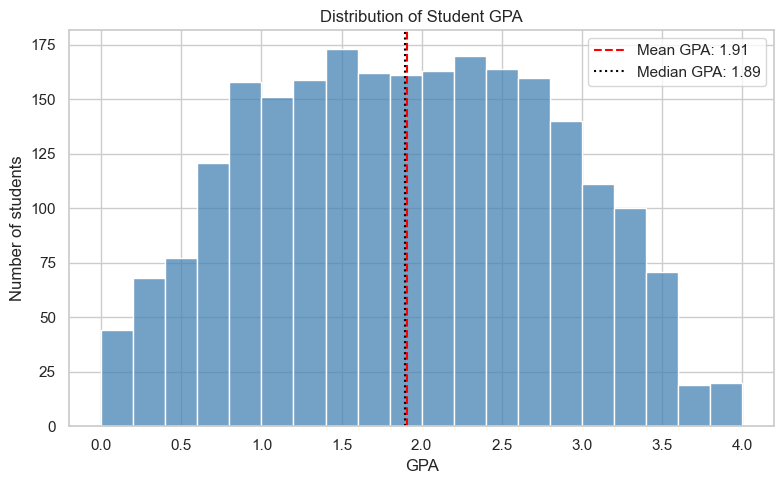

In [15]:
mean_gpa = eda_df[TARGET].mean()
median_gpa = eda_df[TARGET].median()

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=eda_df,
    x=TARGET,
    bins=20,
    color="steelblue",
    ax=ax
)

# Add reference lines for the mean and median.
ax.axvline(
    mean_gpa,
    color="red",
    linestyle="--",
    label=f"Mean GPA: {mean_gpa:.2f}"
)

ax.axvline(
    median_gpa,
    color="black",
    linestyle=":",
    label=f"Median GPA: {median_gpa:.2f}"
)

ax.set(
    title="Distribution of Student GPA",
    xlabel="GPA",
    ylabel="Number of students"
)

ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR / "gpa_distribution.png", dpi=200)
plt.show()

## 3E. Examine study time and absences

### Study Time and Absences

The histograms show the distributions of weekly study time
and absences. The scatterplots examine how each variable
is associated with GPA.

Each scatterplot point represents one student record.
A visible association does not prove a causal relationship.

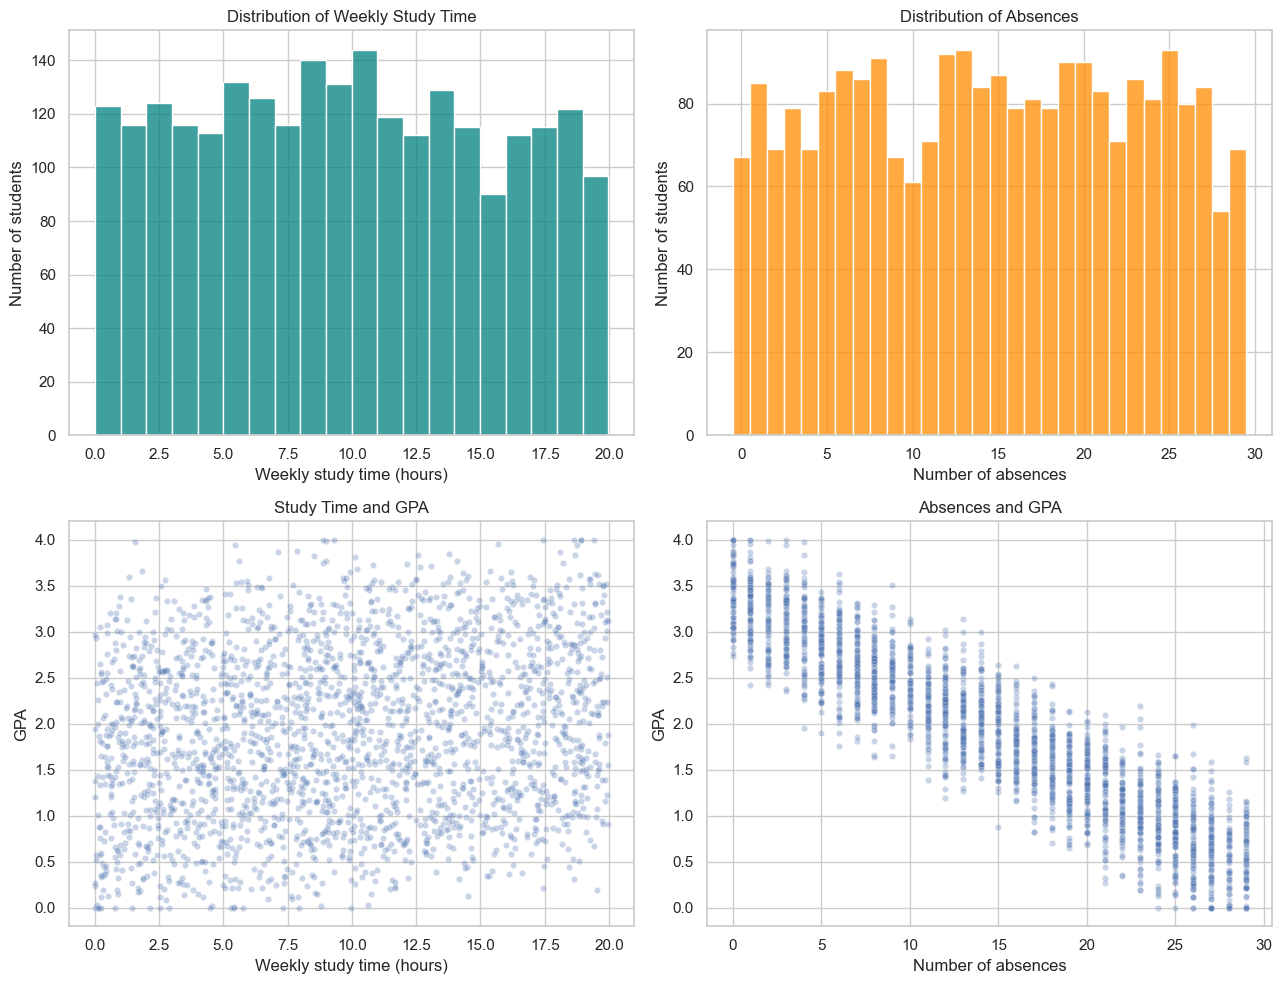

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Distribution of study hours.
sns.histplot(
    data=eda_df,
    x="StudyTimeWeekly",
    bins=20,
    color="teal",
    ax=axes[0, 0]
)
axes[0, 0].set(
    title="Distribution of Weekly Study Time",
    xlabel="Weekly study time (hours)",
    ylabel="Number of students"
)

# Distribution of absence counts.
sns.histplot(
    data=eda_df,
    x="Absences",
    discrete=True,
    color="darkorange",
    ax=axes[0, 1]
)
axes[0, 1].set(
    title="Distribution of Absences",
    xlabel="Number of absences",
    ylabel="Number of students"
)

# Study time compared with GPA.
sns.scatterplot(
    data=eda_df,
    x="StudyTimeWeekly",
    y=TARGET,
    alpha=0.3,
    s=20,
    ax=axes[1, 0]
)
axes[1, 0].set(
    title="Study Time and GPA",
    xlabel="Weekly study time (hours)",
    ylabel="GPA"
)

# Absences compared with GPA.
sns.scatterplot(
    data=eda_df,
    x="Absences",
    y=TARGET,
    alpha=0.3,
    s=20,
    ax=axes[1, 1]
)
axes[1, 1].set(
    title="Absences and GPA",
    xlabel="Number of absences",
    ylabel="GPA"
)

fig.tight_layout()
fig.savefig(
    EDA_DIR / "study_time_and_absences.png",
    dpi=200
)
plt.show()

## 3F. Compare GPA across age and category groups
This includes all remaining selected features without adding any excluded variables.

### GPA Across Selected Groups

Boxplots compare GPA distributions across age groups and
the selected category codes.

The line inside each box marks the median, and the box
contains the middle 50% of observations. Points beyond
the whiskers are not automatically data errors.

Category codes are displayed as recorded in the dataset.
Refer to the variable definitions reviewed in Step 1
when interpreting each category.

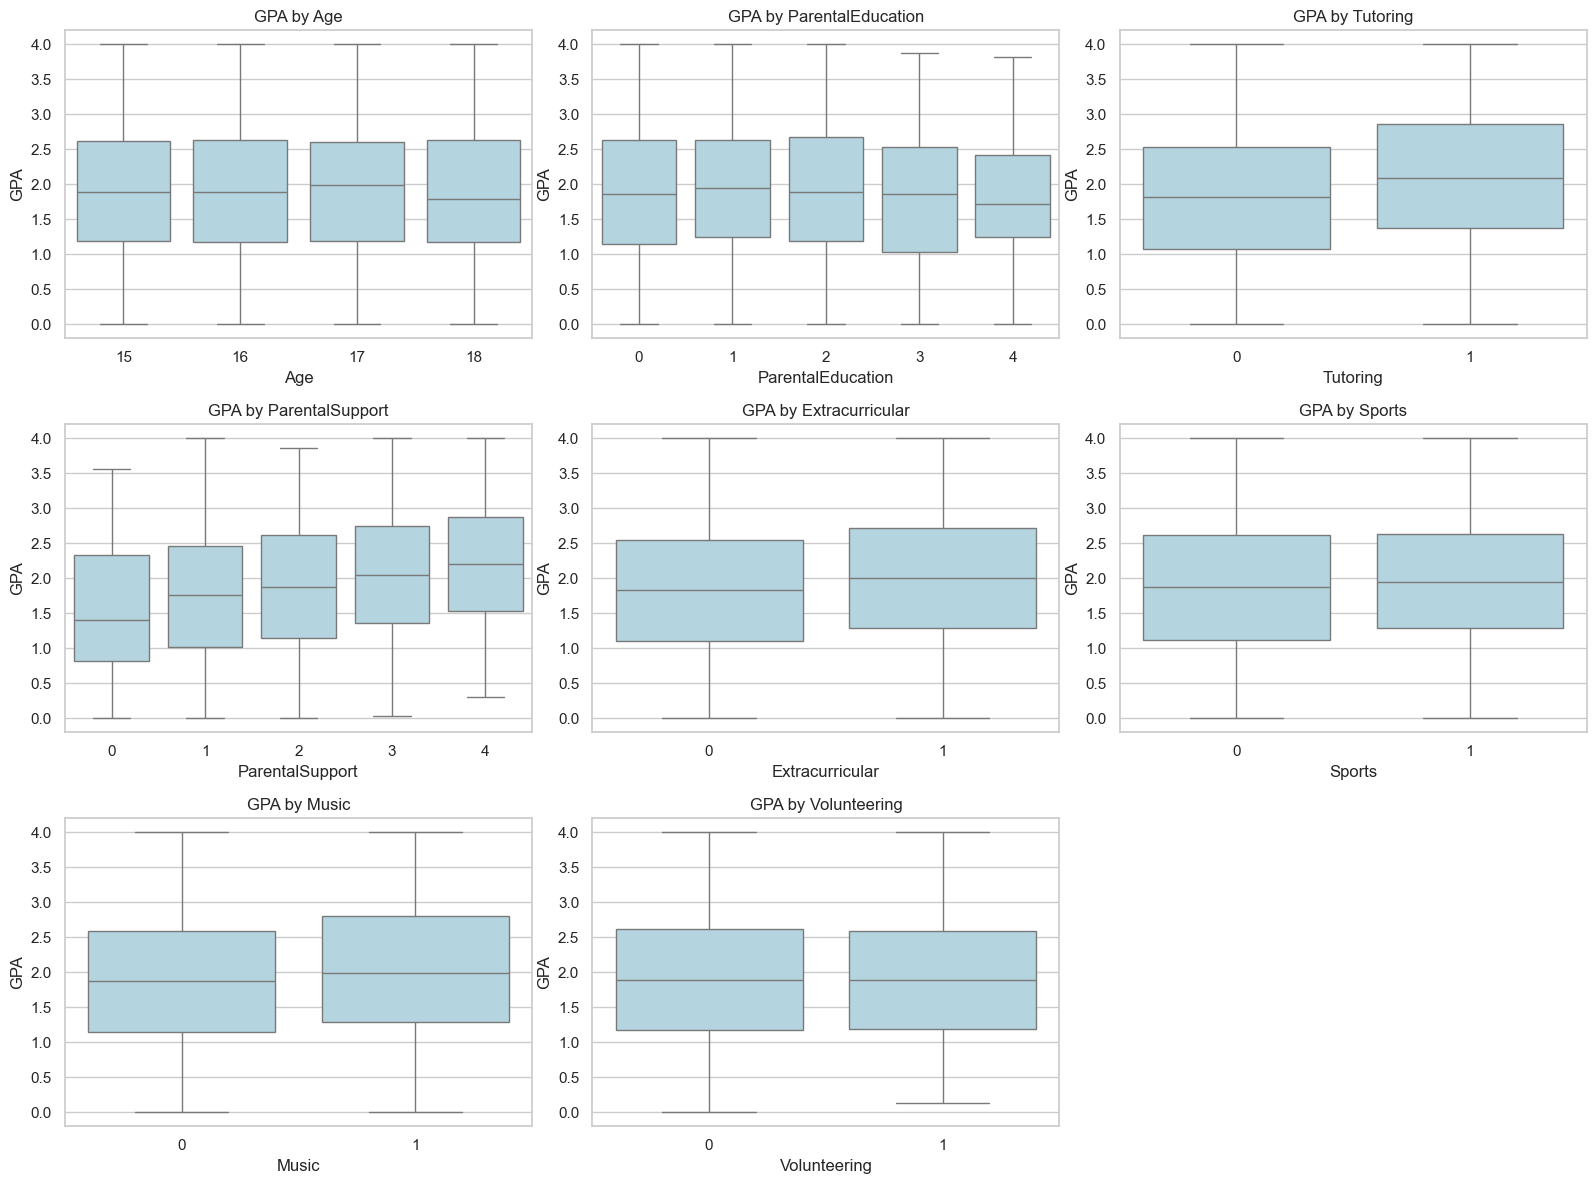

In [17]:
group_columns = [
    column for column in FEATURES
    if column not in ["StudyTimeWeekly", "Absences"]
]

# Create enough panels for the current selected feature list.
n_columns = 3
n_rows = (len(group_columns) + n_columns - 1) // n_columns

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 4 * n_rows),
    squeeze=False
)

flat_axes = axes.ravel()

for ax, column in zip(flat_axes, group_columns):
    category_order = sorted(
        eda_df[column].dropna().unique()
    )

    sns.boxplot(
        data=eda_df,
        x=column,
        y=TARGET,
        order=category_order,
        color="lightblue",
        ax=ax
    )

    ax.set(
        title=f"GPA by {column}",
        xlabel=column,
        ylabel="GPA"
    )

# Hide any unused panels.
for ax in flat_axes[len(group_columns):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig(
    EDA_DIR / "gpa_by_selected_groups.png",
    dpi=200
)
plt.show()

## 3G. Review group sizes and GPA summaries

### Group Sizes and GPA Summaries

Interpret the boxplots alongside the number of records
in each group.

The table reports group size, available GPA count, mean,
median, and standard deviation. Differences between groups
are descriptive and do not establish that group membership
causes changes in GPA.

In [18]:
group_tables = []

for column in group_columns:
    group_summary = (
        eda_df.groupby(column, dropna=False)[TARGET]
        .agg(
            Records="size",
            AvailableGPA="count",
            MeanGPA="mean",
            MedianGPA="median",
            StdGPA="std"
        )
        .reset_index()
        .rename(columns={column: "GroupValue"})
    )

    group_summary.insert(0, "Variable", column)
    group_tables.append(group_summary)

group_summary_table = pd.concat(
    group_tables,
    ignore_index=True
)

display(group_summary_table.round(3))

group_summary_table.to_csv(
    EDA_DIR / "group_gpa_summary.csv",
    index=False
)

,Variable,GroupValue,Records,AvailableGPA,MeanGPA,MedianGPA,StdGPA
0,Age,15,630,630,1.899,1.894,0.920
1,Age,16,593,593,1.908,1.886,0.921
2,Age,17,587,587,1.927,1.992,0.910
3,Age,18,582,582,1.892,1.795,0.911
4,ParentalEducation,0,243,243,1.893,1.856,0.902
5,ParentalEducation,1,728,728,1.944,1.954,0.898
6,ParentalEducation,2,934,934,1.930,1.892,0.931
7,ParentalEducation,3,367,367,1.809,1.856,0.945
8,ParentalEducation,4,120,120,1.816,1.712,0.810
9,Tutoring,0,1671,1671,1.819,1.819,0.906


## 3H. Create a correlation heatmap

### Numerical Correlations

The heatmap summarizes Pearson correlations among age,
study time, absences, and GPA.

Positive values indicate positive linear associations.
Negative values indicate negative linear associations.
Values near zero indicate little linear association,
but do not rule out nonlinear relationships.

Identifiers and coded categories are not included in
this numerical correlation comparison. Correlation is
not causation or model feature importance.

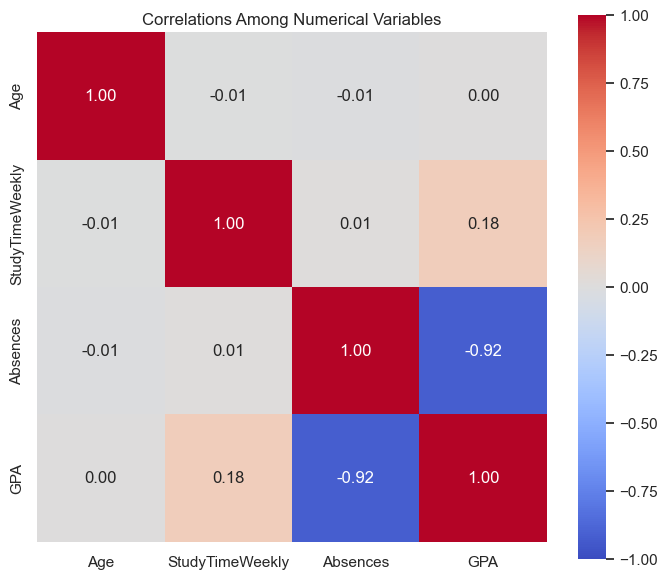

,PearsonCorrelationWithGPA
Absences,-0.919
Age,0.000
StudyTimeWeekly,0.179


In [19]:
correlation_matrix = eda_df[numeric_columns].corr(
    method="pearson"
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Correlations Among Numerical Variables")

fig.tight_layout()
fig.savefig(
    EDA_DIR / "numerical_correlation_heatmap.png",
    dpi=200
)
plt.show()

# Display each numerical input's correlation with the target.
gpa_correlations = (
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values()
    .rename("PearsonCorrelationWithGPA")
)

display(gpa_correlations.to_frame().round(3))

correlation_matrix.to_csv(
    EDA_DIR / "numerical_correlations.csv"
)

## 3I. Add exploration notes — Markdown cell

### Step 3 Review Notes

- GPA distribution:
  GPA ranges from 0.000 to 4.000, with a mean of 1.906 and a median of 1.893. The close mean and median suggest little overall skew, although these statistics alone do not establish the exact distribution shape. The middle 50% of GPAs fall between approximately 1.175 and 2.622, and the standard deviation is 0.915, indicating substantial variation across students.

- Study time and GPA:
  The scatterplot indicates a weak positive association: students reporting more weekly study time tend to have slightly higher GPAs, but GPA varies considerably at similar study-time levels. The Pearson correlation is 𝑟 = 0.179, so weekly study time alone has a limited linear relationship with GPA in this dataset.

- Absences and GPA:
  The scatterplot indicates a strong negative, approximately linear association: students with more absences generally have lower GPAs. The Pearson correlation is 𝑟 = − 0.919, which is much stronger in magnitude than the study-time correlation. This relationship should not be interpreted as evidence that absences alone cause lower GPA.

- Group comparisons:
   - Age: Mean GPAs are very similar across ages 15–18: age 15 has a mean of 1.899 (𝑛 = 630); age 16, 1.908 (𝑛 = 593); age 17, 1.927 (𝑛 = 587); and age 18, 1.892 (𝑛 = 582). There is little descriptive difference in average GPA across these age groups.

   - Tutoring: Students receiving tutoring have a mean GPA of 2.108 (𝑛 = 721), compared with 1.819 for students not receiving tutoring (𝑛 = 1,671), a difference of approximately 0.289 GPA points.

   - Parental support: Mean GPA increases across recorded support levels: none, 1.540 (𝑛 = 212); low, 1.756 (𝑛 = 489); moderate, 1.884 (𝑛 = 740); high, 2.042 (𝑛 = 697); and very high, 2.192 (𝑛 = 254). Group sizes are uneven, and these are unadjusted comparisons.

   - Activities: Students participating in extracurricular activities have a higher mean GPA, 2.015 (𝑛 = 917), than nonparticipants, 1.838 (𝑛 = 1,475). Similar differences appear for sports participants, 1.986 (𝑛 = 726), versus nonparticipants, 1.871 (𝑛 = 1,666), and music participants, 2.042 (𝑛 = 471), versus nonparticipants, 1.873 (𝑛 = 1,921). Volunteering shows almost no mean difference: 1.913 for participants (𝑛 = 376) versus 1.905 for nonparticipants (𝑛 = 2,016).



- Data-quality concerns:
  The dataset contains 2,392 records, with no missing values, exact duplicate rows, missing student identifiers, or repeated student identifiers. All GPA values are numeric and within the notebook’s expected 0–4 range. However, the earlier review notes a documentation discrepancy: the source description states a GPA range of 2.0–4.0, while the observed values span 0.0–4.0. Retain values below 2.0 unless further investigation establishes that they are erroneous. The unusually strong absence–GPA relationship also warrants investigation, especially because the dataset is documented as synthetically generated. Consistency between GradeClass and GPA has not yet been tested. Do not automatically remove boundary values or boxplot outliers merely because they look unusual.

- Limitations:
  The findings describe associations in this dataset, not causal effects or prediction accuracy. Group comparisons do not adjust for other variables, and some groups have substantially different sample sizes. Because the dataset is synthetic and intended for educational use, its patterns may not generalize to real student populations. Excluding demographic inputs does not guarantee fairness.

- Next step:
  Prepare the selected variables for modeling and document the
  training/testing procedure and preprocessing decisions.

- Reviewer and review date:
  [Enter name and actual review date.]